# ROUTES: Análisis Exploratorio de Datos y Caracterización de la Flota Comercial

El archivo `routes.txt` opera como el catálogo estructural de las líneas de autobús vigentes de la EMT de Madrid, definiendo los identificadores comerciales y los itinerarios de la red de transporte de superficie. Para el modelo predictivo, este dataset representa el esqueleto relacional básico, ya que clasificar correctamente la tipología y el régimen de operación de cada línea permite al algoritmo asimilar de forma agregada el comportamiento de la varianza en los retrasos según el tipo de servicio.

### Objetivos del Diagnóstico:
1. **Consistencia Estructural:** Sanear la matriz de entrada mediante la eliminación de dimensionalidad muerta (constantes redundantes o vectores con nulidad absoluta) y validar la unicidad de las claves primarias comerciales.

2. **Ingeniería de Características Horarias:** Desarrollar variables categóricas de negocio para segmentar las líneas según su régimen horario de operación (Servicio Diurno Regular, Red Radial de Búhos Nocturnos o Servicios Circulares Ininterrumpidos).

3. **Análisis de Centralización Territorial:** Evaluar los nudos geográficos de inyección masiva de la flota y medir la dispersión capilar de la red para alimentar el modelo con patrones de comportamiento policéntrico o monocéntrico de las cabeceras.

Iniciamos el flujo de ingeniería de datos realizando una inspección estructural preliminar para auditar la dimensionalidad y consistencia de los vectores de entrada del conjunto de datos de `routes`.

In [1]:
# Importación de librerias y configuración del entorno
import os
import logging
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("====== INICIANDO CARGA OPTIMIZADA DE MAESTRO DE RUTAS (PANDAS PYARROW) ======\n")

# 1. Definimos el esquema de tipos estricto usando el motor de PyArrow para optimizar memoria RAM
# Mapeamos el 100% de la estructura física del estándar original de la EMT de Madrid
routes_dtypes = {
    "route_id": "string[pyarrow]",
    "agency_id": "string[pyarrow]",
    "route_short_name": "string[pyarrow]",
    "route_long_name": "string[pyarrow]",
    "route_desc": "float64",          # Detectado como numérico/nulo en bruto
    "route_type": "int64",
    "route_url": "string[pyarrow]",
    "route_color": "string[pyarrow]",
    "route_text_color": "string[pyarrow]"
}

# 2. Cargamos el archivo original aplicando el esquema de tipado binario ligero
routes = pd.read_csv('../data/raw/gtfs/routes.txt', encoding='utf-8', dtype=routes_dtypes)

# 3. Saneamiento estricto de claves primarias: Forzamos relleno de ceros a 3 dígitos (zfill)
routes['route_id'] = routes['route_id'].str.zfill(3)

print("====== ESTRUCTURA INICIAL OPTIMIZADA EN MEMORIA (PYARROW SCHEMA) ======\n")
print(routes.info())

print("\nMuestra forense preliminar de los primeros registros en bruto (Todas las columnas):")
display(routes.head(5))


====== INICIANDO CARGA OPTIMIZADA DE MAESTRO DE RUTAS (PANDAS PYARROW) ======

====== ESTRUCTURA INICIAL OPTIMIZADA EN MEMORIA (PYARROW SCHEMA) ======

<class 'pandas.DataFrame'>
RangeIndex: 236 entries, 0 to 235
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   route_id          236 non-null    string 
 1   agency_id         236 non-null    string 
 2   route_short_name  236 non-null    string 
 3   route_long_name   236 non-null    string 
 4   route_desc        0 non-null      float64
 5   route_type        236 non-null    int64  
 6   route_url         236 non-null    string 
 7   route_color       236 non-null    string 
 8   route_text_color  236 non-null    string 
dtypes: float64(1), int64(1), string(7)
memory usage: 40.6 KB
None

Muestra forense preliminar de los primeros registros en bruto (Todas las columnas):


,route_id,agency_id,route_short_name,route_long_name,route_desc,route_type,route_url,route_color,route_text_color
0,001,EMT,1,Plaza de Cristo Rey - Prosperidad,NaN,3,https://www.emtmadrid.es/EMTBUS/Mi-linea?linea=1,0178BC,FFFFFF
1,002,EMT,2,Plaza de Manuel Becerra - Avenida Reina Victoria,NaN,3,https://www.emtmadrid.es/EMTBUS/Mi-linea?linea=2,0178BC,FFFFFF
2,003,EMT,3,Puerta de Toledo - Plaza de San Amaro,NaN,3,https://www.emtmadrid.es/EMTBUS/Mi-linea?linea=3,0178BC,FFFFFF
3,004,EMT,4,Plaza de Ciudad Lineal - Puerta de Arganda,NaN,3,https://www.emtmadrid.es/EMTBUS/Mi-linea?linea=4,0178BC,FFFFFF
4,005,EMT,5,Puerta del Sol/sevilla - Estacion de Chamartin,NaN,3,https://www.emtmadrid.es/EMTBUS/Mi-linea?linea=5,0178BC,FFFFFF


### Diagnóstico de Dimensionalidad y Auditoría de Completitud Estructural

La inspección preliminar de los tipos de datos a través de la salida del método `.info()` revela que el catálogo de líneas comerciales presenta un alto índice de completitud, con una única excepción estructural: la variable `route_desc`, la cual carece por completo de registros válidos (`0 non-null`) en la muestra en bruto. Por el contrario, los ocho campos restantes —incluyendo metadatos de agencia, enlaces web y parametrizaciones cromáticas de las líneas— se encuentran poblados al 100% con sus 236 registros originales, gestionados de forma eficiente bajo el motor binario de PyArrow (`string`).

**Criterio Técnico de Negocio y Modelado:**
En la arquitectura de datos de la EMT de Madrid, la prescisión e información en el campo `route_desc` responde a que las particularidades operativas e itinerarios de las líneas ya quedan completamente cubiertas y tipificadas de forma explícita por las variables de nombre corto (`route_short_name`) y nombre largo (`route_long_name`). Al no existir anotaciones adicionales necesarias para la explotación del servicio, esta columna se identifica como dimensionalidad muerta sin varianza analítica. Este hallazgo justifica metodológicamente su eliminación en la fase de optimización, junto con el descarte selectivo de variables constantes o metadatos irrelevantes para el algoritmo predictivo (como tipos de ruta homogéneos o URLs externas), resguardando de forma óptima la ligereza de la memoria RAM de trabajo.

### 📘 Diccionario de Datos

Este notebook utiliza el diccionario de datos definido para el conjunto `routes`.  

El documento completo se encuentra en:

👉 [`../docs/01_routes_Dict.md`](../docs/01_routes_Dict.md)

| Columna | Tipo de Dato (Pandas) | Descripción de Negocio | Rol en el Modelo / Importancia |
| :--- | :--- | :--- | :--- |
| **`route_id`** | `String` a `string[pyarrow]` | Identificador alfanumérico único e interno de la línea comercial asignado por el consorcio (e.g., `001`, `203`). | **Clave Primaria**. Indexador principal para mapear la red y realizar cruces relacionales con `trips`. |
| **`agency_id`** | `String` a `string[pyarrow]` | Identificador de la agencia operadora del servicio (EMT Madrid). | **Variable Descartada**. Se elimina en la fase de optimización debido a que es una constante redundante sin varianza. |
| **`route_short_name`** | `String` a `string[pyarrow]` | Código corto comercial visible para el usuario en el autobús y marquesinas (e.g., `1`, `E1`, `N25`). | **Variable Predictora**. Variable de texto raíz utilizada para extraer las características del régimen horario. |
| **`route_long_name`** | `String` a `string[pyarrow]` | Nombre descriptivo largo oficial que define el itinerario comercial uniendo los dos extremos (e.g., `CRISTO REY - PROSPERIDAD`). | **Variable Descriptiva**. Variable compuesta raíz utilizada para el desglose e ingeniería de terminales físicas. |
| **`route_desc`** | `Float64` a `float64` | Descripción extendida u observaciones adicionales sobre las particularidades de la línea. | **Variable Descartada**. Se elimina por presentar nulidad absoluta (100% nulos) sin valor analítico. |
| **`route_type`** | `Int64` a `int64` | Código numérico que define el modo de transporte según el estándar GTFS (el valor `3` identifica autobús urbano). | **Variable Descartada**. Se elimina al ser una constante homogénea para el 100% de la flota de superficie. |
| **`route_url`** | `String` a `string[pyarrow]` | Enlace web oficial a los horarios, tarifas y desvíos específicos de la línea en el portal de la EMT. | **Variable Descartada**. Se elimina al tratarse de metadatos externos irrelevantes para el algoritmo. |
| **`route_color`** | `String` a `string[pyarrow]` | Código hexadecimal del color corporativo asignado para la representación en planos e interfaces (e.g., `0056B3`). | **Variable Descartada**. Se elimina por tratarse de un atributo puramente estético de representación gráfica. |
| **`route_text_color`** | `String` a `string[pyarrow]` | Código hexadecimal del color para el texto sobre el fondo de la línea en interfaces gráficas. | **Variable Descartada**. Se elimina por tratarse de un atributo puramente estético sin aporte predictivo. |
| **`cabecera_ruta`** | `Nueva` a `string[pyarrow]` | Punto geográfico, estación o terminal física donde nace formalmente el recorrido del trayecto (e.g., `PLAZA DE CIBELES`). | **Feature Engineering**. Variable operativa clave para agrupar e identificar los nudos masivos de inyección de la flota. |
| **`destino_ruta`** | `Nueva` a `string[pyarrow]` | Punto geográfico o terminal física donde finaliza formalmente el recorrido del trayecto (e.g., `VILLAVERDE ALTO`). | **Feature Engineering**. Variable operativa clave para medir el nivel de dispersión capilar y la distribución en barrios residenciales. |
| **`regimen_horario`** | `Nueva` a `string[pyarrow]` | Clasificación operativa de la línea según su ventana temporal de explotación (`Servicio Diurno`, `Servicio Nocturno (Búho)` o `Servicio 24 Horas`). | **Feature Engineering**. Variable predictora crítica que inyecta al modelo el contexto de fricción del tráfico por franja. |

### Control de Duplicados e Integridad de Claves

Antes de proceder con las transformaciones de negocio, es indispensable auditar el conjunto de datos en busca de registros redundantes o conflictos estructurales. Se implementa una estrategia de control dividida en dos dimensiones complementarias:

1. **Duplicados Absolutos (Redundancia en Bruto):** Evaluación sobre la presencia de filas que sean 100% idénticas en todas y cada una de sus columnas. Este escenario suele estar provocado por fallos en la persistencia o anomalías en la descompresión del archivo `routes.txt` original. Su eliminación es directa y libre de riesgo analítico, ya que no aporta información nueva al modelo.

2. **Colisiones de Clave Primaria (Conflictos de Identidad):** Auditoría específica sobre la columna de clave primaria `route_id`. Se identifican registros que compartan el mismo identificador único pero que almacenen valores distintos en sus variables de texto comerciales. Desde la perspectiva analítica, este escenario es crítico: una colisión aquí rompería la integridad referencial de la malla del transporte al realizar cruces posteriores, duplicando líneas de forma exponencial en memoria y alterando las predicciones estadísticas de regularidad de la red.

El objetivo de esta fase es cuantificar ambas métricas para determinar si los desajustes responden a ruido técnico ordinario o si exigen el desvío forense de los identificadores corruptos hacia el módulo de cuarentena para preservar la salud del pipeline.

In [2]:
print("====== REPORTE DE CONTROL DE DUPLICADOS EN BRUTO (ROUTES) ======\n")

# 1. Cuantificación de redundancias absolutas y colisiones de clave primaria
total_duplicados = routes.duplicated().sum()
duplicados_clave = routes['route_id'].duplicated().sum()

print(f"-> Filas 100% idénticas duplicadas detectadas: {total_duplicados}")
print(f"-> Rutas con el mismo 'route_id' en conflicto:   {duplicados_clave}")

# 2. Cláusulas de control y evaluación de acciones correctivas defensivas
if total_duplicados > 0:
    print("\nMuestra forense de líneas 100% idénticas repetidas:")
    df_duplicados_completos = routes[routes.duplicated(keep=False)]
    display(df_duplicados_completos.sort_values(by=['route_id']))
    print("\n[RESOLUCIÓN BACKEND]: Aplicación de '.drop_duplicates()' en 'src/limpieza.py'.")

if duplicados_clave > 0:
    print("\n¡ALERTA CRÍTICA! Conflictos graves de identidad en la clave 'route_id':")
    df_duplicados_clave = routes[routes.duplicated(subset=['route_id'], keep=False)]
    display(df_duplicados_clave.sort_values(by=['route_id']))
    print("\n[RESOLUCIÓN BACKEND]: Las colisiones de clave corrompen las reglas de negocio de la EMT. "
          "Estos registros duplicados se desviarán por completo al módulo de cuarentena.")
else:
    print("\nTodo limpio: Cada 'route_id' representa una línea comercial única en la base de datos.")


====== REPORTE DE CONTROL DE DUPLICADOS EN BRUTO (ROUTES) ======

-> Filas 100% idénticas duplicadas detectadas: 0
-> Rutas con el mismo 'route_id' en conflicto:   0

Todo limpio: Cada 'route_id' representa una línea comercial única en la base de datos.


### Optimización Estructural y Extracción de Variables Operativas

El análisis del catálogo comercial de la EMT de Madrid permite prescindir de aquellos metadatos y constantes homogéneas que no aportan varianza analítica al modelo predictivo de puntualidad. Se ejecuta una purga física directa eliminando las columnas `agency_id`, `route_desc`, `route_type`, `route_url`, `route_color` y `route_text_color` para aligerar la huella en memoria RAM de la matriz de trabajo.

Simultáneamente, se procesa la variable compuesta `route_long_name` mediante una segmentación de cadena (*split*) para aislar los dos extremos físicos del itinerario comercial, dando origen a las variables operativas `cabecera_ruta` y `destino_ruta`. Con el fin de evitar discrepancias de caja o la presencia de espacios en blanco marginales, se aplica un protocolo vectorizado de normalización masiva forzando la conversión a mayúsculas y asegurando la persistencia de los nuevos vectores bajo el tipo de dato optimizado de alta velocidad de PyArrow.

In [3]:
print("====== OPTIMIZACIÓN ESTRUCTURAL Y SANITIZACIÓN VECTORIAL EN PANDAS ======\n")

# 1. Purgamos las columnas muertas identificadas en la fase forense previa
columnas_a_eliminar = ['agency_id', 'route_desc', 'route_type', 'route_url', 'route_color', 'route_text_color']
routes = routes.drop(columns=columnas_a_eliminar)

# 2. Segmentamos el nombre extendido para extraer los extremos e imponemos el dtype PyArrow
routes[['cabecera_ruta', 'destino_ruta']] = (
    routes['route_long_name']
    .astype(str)
    .str.split(' - ', n=1, expand=True)
    .astype("string[pyarrow]")
)

# 3. MOTOR VECTORIAL MASIVO: Saneamiento de espacios y forzado a mayúsculas
routes = routes.assign(
    route_long_name=routes['route_long_name'].str.strip().str.upper(),
    cabecera_ruta=routes['cabecera_ruta'].str.strip().str.upper(),
    destino_ruta=routes['destino_ruta'].str.strip().str.upper()
)

# 4. Neutralizamos cadenas vacías o textos trampa convirtiéndolos en nulos reales de Pandas
routes['destino_ruta'] = routes['destino_ruta'].replace(['', 'NAN', 'NONE'], pd.NA)

print("-> Estructura física aligerada y vectores normalizados con éxito.")
print(f"-> Dimensiones actuales de la matriz de rutas: {routes.shape[0]} filas y {routes.shape[1]} columnas.")
print(f"-> Esquema de variables remanentes en producción: {list(routes.columns)}\n")

print("Muestra del inventario resultante de variables operativas:")
display(routes.head(5))


====== OPTIMIZACIÓN ESTRUCTURAL Y SANITIZACIÓN VECTORIAL EN PANDAS ======

-> Estructura física aligerada y vectores normalizados con éxito.
-> Dimensiones actuales de la matriz de rutas: 236 filas y 5 columnas.
-> Esquema de variables remanentes en producción: ['route_id', 'route_short_name', 'route_long_name', 'cabecera_ruta', 'destino_ruta']

Muestra del inventario resultante de variables operativas:


,route_id,route_short_name,route_long_name,cabecera_ruta,destino_ruta
0,001,1,PLAZA DE CRISTO REY - PROSPERIDAD,PLAZA DE CRISTO REY,PROSPERIDAD
1,002,2,PLAZA DE MANUEL BECERRA - AVENIDA REINA VICTORIA,PLAZA DE MANUEL BECERRA,AVENIDA REINA VICTORIA
2,003,3,PUERTA DE TOLEDO - PLAZA DE SAN AMARO,PUERTA DE TOLEDO,PLAZA DE SAN AMARO
3,004,4,PLAZA DE CIUDAD LINEAL - PUERTA DE ARGANDA,PLAZA DE CIUDAD LINEAL,PUERTA DE ARGANDA
4,005,5,PUERTA DEL SOL/SEVILLA - ESTACION DE CHAMARTIN,PUERTA DEL SOL/SEVILLA,ESTACION DE CHAMARTIN


### Transformación de Datos: Ingeniería de Características para el Régimen Horario

Con el objetivo de dotar al modelo predictivo de un contexto operativo robusto, se procede a aplicar ingeniería de características sobre la variable `route_short_name` para segmentar el catálogo de líneas en tres regímenes horarios rígidos: **Servicio Diurno Regular**, **Servicio Nocturno (Búho)** y **Servicio 24 Horas**.

Esta segmentación responde estrictamente a las reglas de negocio oficiales de la EMT de Madrid:
1. **Servicio Nocturno (Búho):** Identificado en el estándar GTFS madrileño por comenzar con la letra **'N'** (red radial de autobuses nocturnos centrada en Cibeles) o **'NC'** (líneas circulares nocturnas que conectan en anillo Cuatro Caminos y Atocha).

2. **Servicio 24 Horas:** Reservado para la **Línea 203 (Exprés Aeropuerto)**, el único trayecto de la red que mantiene una ventana de explotación ininterrumpida durante todo el año.

3. **Servicio Diurno Regular:** Comprende el grueso de la flota (numeración estándar, líneas exprés 'E' y lanzaderas especiales 'SE') que operan vinculadas al tráfico laboral y escolar tradicional.

Disponer de esta clasificación permite aislar los patrones de varianza: las líneas nocturnas se enfrentan a congestión vial reducida pero a penalizaciones de tiempo por bajas frecuencias, mientras que las diurnas absorben los cuellos de botella de las horas punta de la ciudad.

In [4]:
print("====== FEATURE ENGINEERING: RÉGIMEN HORARIO DE OPERACIÓN ======\n")

# 1. Normalizamos temporalmente el vector corto comercial para asegurar la consistencia de las máscaras
codigo_comercial = routes['route_short_name'].str.strip().str.upper()

# 2. Definimos las condiciones lógicas de negocio basadas en el estándar GTFS de Madrid
condiciones = [
    codigo_comercial.str.startswith('N'),
    (codigo_comercial == '203') | (codigo_comercial.str.contains('AEROPUERTO', na=False))
]

# 3. Asignamos las categorías correspondientes a cada regla operativa
categorias = [
    'Servicio Nocturno (Búho)',
    'Servicio 24 Horas'
]

# 4. Evaluamos vectorialmente las matrices inyectando la nueva variable categórica
# Especificamos explícitamente el dtype string[pyarrow] para preservar la optimización de memoria
routes['regimen_horario'] = np.select(condiciones, categorias, default='Servicio Diurno Regular')
routes['regimen_horario'] = routes['regimen_horario'].astype("string[pyarrow]")

# 5. Validación de consistencia y balanceo de las nuevas clases en la terminal
print("Distribución de las frecuencias absolutas por régimen de operación:")
print(routes['regimen_horario'].value_counts())

====== FEATURE ENGINEERING: RÉGIMEN HORARIO DE OPERACIÓN ======

Distribución de las frecuencias absolutas por régimen de operación:
regimen_horario
Servicio Diurno Regular     203
Servicio Nocturno (Búho)     32
Servicio 24 Horas             1
Name: count, dtype: int64[pyarrow]


### Diagnóstico de Completitud y Gestión de Valores Ausentes

Una vez depurada la estructura dimensional de la matriz transaccional, se procede a realizar un diagnóstico sistemático sobre la integridad y completitud de las variables críticas supervivientes. Se cuantifica la presencia de registros nulos o valores faltantes (`NaN` / `None`) desglosados por columna para evaluar la salud interna del catálogo de la flota de la EMT de Madrid.

Desde la perspectiva analítica y relacional, el control de nulos en este dataset es severo: cualquier ausencia de datos en variables raíz como el identificador de la línea (`route_id`) o las nomenclaturas comerciales (`route_short_name`, `route_long_name`) constituye una anomalía crítica que inhabilitaría la integridad referencial del modelo relacional. El objetivo de este bloque es auditar volumétricamente estas omisiones técnicas para justificar los criterios de depuración defensiva o el aislamiento forzado de los registros huérfanos hacia el módulo de cuarentena antes de dar paso a los análisis geo-operativos avanzados.

In [5]:
print("====== AUDITORÍA SISTEMÁTICA DE COMPLETITUD DE VARIABLES ======\n")

# 1. Cuantificación de registros ausentes por columna
conteo_nulos_columna = routes.isna().sum()
total_filas_incompletas = routes.isna().any(axis=1).sum()

print("Inventario de registros ausentes por columna:")
print(conteo_nulos_columna)

# 2. Aislamiento y despliegue visual de registros incompletos
if total_filas_incompletas > 0:
    print(f"\n[EVIDENCIA] Se han detectado {total_filas_incompletas} registros con valores faltantes tras la segmentación:")
    df_registros_incompletos = routes[routes.isna().any(axis=1)]
    display(df_registros_incompletos)

====== AUDITORÍA SISTEMÁTICA DE COMPLETITUD DE VARIABLES ======

Inventario de registros ausentes por columna:
route_id            0
route_short_name    0
route_long_name     0
cabecera_ruta       0
destino_ruta        2
regimen_horario     0
dtype: int64

[EVIDENCIA] Se han detectado 2 registros con valores faltantes tras la segmentación:


,route_id,route_short_name,route_long_name,cabecera_ruta,destino_ruta,regimen_horario
66,068,C1,CIRCULAR 1 -,CIRCULAR 1,<NA>,Servicio Diurno Regular
67,069,C2,CIRCULAR 2 -,CIRCULAR 2,<NA>,Servicio Diurno Regular


### Tratamiento de Omisiones de Destino en Líneas Circulares

La auditoría de completitud arroja un saldo exclusivo de dos registros incompletos localizados en la columna `destino_ruta`. La inspección forense de las filas delata que las omisiones corresponden de forma unívoca a las líneas de fisonomía de anillo de la capital (`CIRCULAR 1` y `CIRCULAR 2`), donde el sistema de origen de la EMT de Madrid trunca la cadena tras registrar la cabecera.

Para automatizar la resolución de este comportamiento geométrico, incluso ante la futura inyección de nuevas líneas en anillo en el catálogo, se diseña un algoritmo de rescate indexado. La regla de negocio estipula que, ante cualquier registro donde la cabecera contenga el patrón lexicográfico 'CIRCULAR' y el destino se encuentre ausente, se procederá a duplicar el valor de la cabecera en el vector de destino. Esto convalida la coherencia de bucle cerrado de los itinerarios y restaura la simetría relacional de la matriz transaccional.

In [6]:
print("====== EJECUCIÓN DEL ALGORITMO DE RESCATE: LÍNEAS CIRCULARES (EMT) ======\n")

# 1. Definimos las máscaras booleanas vectorizadas sobre la matriz operativa
filtro_circular = routes['cabecera_ruta'].str.contains('CIRCULAR', na=False)
destino_ausente = routes['destino_ruta'].isna()
mascara_rescate = filtro_circular & destino_ausente

# 2. Evaluamos e imputamos de forma controlada el valor de la cabecera en el destino
if mascara_rescate.any():
    num_lineas_rescatadas = mascara_rescate.sum()
    print(f"-> Regla de negocio activada: Se han identificado {num_lineas_rescatadas} líneas circulares sin destino.")
    
    # Imputación directa sobre las celdas afectadas
    routes.loc[mascara_rescate, 'destino_ruta'] = routes.loc[mascara_rescate, 'cabecera_ruta']
    
    # Saneamiento de caracteres residuales en los extremos de la cabecera
    routes['cabecera_ruta'] = routes['cabecera_ruta'].str.rstrip(' -').str.strip()
    
    # Blindaje de integridad: Forzamos la persistencia estricta del tipo de dato PyArrow
    routes['destino_ruta'] = routes['destino_ruta'].astype("string[pyarrow]")
    routes['cabecera_ruta'] = routes['cabecera_ruta'].astype("string[pyarrow]")
    
    print("-> Saneamiento de anillo completado y tipos de memoria PyArrow consolidados.")
else:
    print("-> No se requieren acciones de mitigación: La estructura de paradas circulares es conforme.")


====== EJECUCIÓN DEL ALGORITMO DE RESCATE: LÍNEAS CIRCULARES (EMT) ======

-> Regla de negocio activada: Se han identificado 2 líneas circulares sin destino.
-> Saneamiento de anillo completado y tipos de memoria PyArrow consolidados.


### Validación Final de la Integridad de la Matriz Transaccional

Una vez ejecutadas las reglas de negocio de mitigación sobre los vectores de itinerario, se procede a formalizar una auditoría de cierre sobre la completitud global del catálogo. Se evalúa nuevamente la presencia de valores ausentes en la totalidad de las columnas supervivientes con el objetivo de certificar el estado inmaculado de los datos antes de habilitar las validaciones lógicas de atípicos. 

En caso de detectarse registros incompletos residuales que no hayan podido ser subsanados por los algoritmos de dominio, se establecerá un criterio defensivo de desvío inmediato hacia el módulo de cuarentena en el backend de producción para no contaminar la integridad del pipeline relacional.

In [7]:
print("====== VALIDACIÓN DE CIERRE: CONTROL DE CALIDAD DE COMPLETITUD ======\n")

# 1. Cómputo final de la tasa de nulidad residual en el DataFrame
conteo_nulos_finales = routes.isna().sum()
total_nulos_finales = routes.isna().any(axis=1).sum()

print("Inventario de registros ausentes de cierre por columna:")
print(conteo_nulos_finales)

# 2. Evaluación de integridad y propuesta de acciones correctivas finales
if total_nulos_finales > 0:
    print(f"\n¡Atención! Se han aislado {total_nulos_finales} filas con nulos reales incorregibles:")
    df_nulos_reales = routes[routes.isna().any(axis=1)]
    display(df_nulos_reales)
    print("\n[RESOLUCIÓN BACKEND]: Registros inválidos irreparables. "
          "Se programará su desvío automático hacia el archivo de cuarentena.")
else:
    print("\nTodo limpio: El 100% de los registros operativos están completos (cero valores nulos).")

====== VALIDACIÓN DE CIERRE: CONTROL DE CALIDAD DE COMPLETITUD ======

Inventario de registros ausentes de cierre por columna:
route_id            0
route_short_name    0
route_long_name     0
cabecera_ruta       0
destino_ruta        0
regimen_horario     0
dtype: int64

Todo limpio: El 100% de los registros operativos están completos (cero valores nulos).


### Control de Valores Atípicos (Outliers) de Negocio

En el catálogo de líneas comerciales de la EMT de Madrid, la detección de valores atípicos se rige por reglas lógicas de dominio sobre la consistencia de los identificadores y las longitudes comerciales de las terminales. Se auditan dos escenarios críticos de control:

1. **Malformación del Código Comercial (`route_short_name`):** Identificación de registros donde el código visible del autobús venga vacío, contenga caracteres corruptos o presente una longitud ilógica. Una línea reglamentaria de la EMT se compone de entre 1 y 5 caracteres como máximo (e.g., '1', '74', 'E1', 'SE702'). Una longitud superior delata anomalías de estructura o fallos en la carga del archivo de origen.

2. **Incoherencia en la Extracción de Terminales (`cabecera_ruta` o `destino_ruta`):** Verificación de que, tras la segmentación del nombre extendido, ninguna de las terminales físicas registre longitudes atípicamente cortas (menos de 3 caracteres). Este escenario delataría una ruptura, truncado o corrupción del texto original en la base de datos relacional del consorcio.

In [9]:
print("====== REPORTE DE CONTROL DE VALORES ATÍPICOS EN LA FLOTA (ROUTES) ======\n")

# 1. Auditoría del código comercial corto basándose en límites de longitud operativa
codigos_comerciales_anomalos = routes[
    (routes['route_short_name'].str.strip() == "") | 
    (routes['route_short_name'].isna()) |
    (routes['route_short_name'].str.len() > 5)
]

# 2. Auditoría forense de textos en las terminales físicas detectando truncados estructurales
terminales_atipicas = routes[
    ((routes['cabecera_ruta'].str.len() < 3) & routes['cabecera_ruta'].notnull()) |
    ((routes['destino_ruta'].str.len() < 3) & routes['destino_ruta'].notnull())
]

print(f"-> Registros con códigos comerciales corruptos o de longitud atípica (>5): {len(codigos_comerciales_anomalos)}")
print(f"-> Registros con nombres de cabecera/destino atípicamente truncados (<3):   {len(terminales_atipicas)}")

# 3. Cláusulas de control y toma de decisiones operativas de backend
if len(codigos_comerciales_anomalos) > 0 or len(terminales_atipicas) > 0:
    print("\n¡ALERTA DE CONSISTENCIA! Se han detectado anomalías lógicas en las variables operativas:")
    if len(codigos_comerciales_anomalos) > 0:
        display(codigos_comerciales_anomalos)
    if len(terminales_atipicas) > 0:
        display(terminales_atipicas)
    print("\n[RESOLUCIÓN BACKEND]: Estos registros deforman la jerarquía del catálogo. "
          "Se programará su aislamiento y desvío automático hacia el archivo de cuarentena.")
else:
    print("\nTodo limpio: El 100% de las rutas comerciales presentan longitudes e identificadores coherentes de negocio.")


====== REPORTE DE CONTROL DE VALORES ATÍPICOS EN LA FLOTA (ROUTES) ======

-> Registros con códigos comerciales corruptos o de longitud atípica (>5): 0
-> Registros con nombres de cabecera/destino atípicamente truncados (<3):   0

Todo limpio: El 100% de las rutas comerciales presentan longitudes e identificadores coherentes de negocio.


### Caracterización Estadística y Auditoría Dimensional de la Flota

Una vez consolidadas las fases de depuración estructural y saneamiento de nulos, se procede a realizar un análisis de cardinalidad y distribución estadística sobre las variables categóricas de la red comercial. Este diagnóstico dimensional es clave para validar la consistencia de las agrupaciones operativas y asegurar que las frecuencias de las cabeceras e itinerarios reflejen fielmente las reglas de negocio de la EMT de Madrid antes de transferir el conjunto de datos refinado al modelo predictivo.

In [10]:
print("====== CARACTERIZACIÓN ESTADÍSTICA DE VECTORES CUALITATIVOS ======\n")

# Cuantificación de la cardinalidad, modas y frecuencias de las variables categóricas
resumen_cardinalidad = routes.describe(include=['string'])

# Despliegue de la matriz de control dimensional
display(resumen_cardinalidad)

====== CARACTERIZACIÓN ESTADÍSTICA DE VECTORES CUALITATIVOS ======



,route_id,route_short_name,route_long_name,cabecera_ruta,destino_ruta,regimen_horario
count,236,236,236,236,236,236
unique,236,236,226,69,136,3
top,001,1,PLAZA DE CIBELES - PALOMERAS,PLAZA DE CIBELES,VILLAVERDE ALTO,Servicio Diurno Regular
freq,1,1,2,28,6,203


La explotación de la matriz de cardinalidad revela la existencia de 226 valores únicos en el vector `route_long_name` frente a un total de 236 registros. Esta discrepancia geométrica no delata anomalías de duplicidad, sino un comportamiento legítimo del negocio: existen líneas que, compartiendo idénticos puntos de cabecera y destino, se bifurcan en itinerarios comerciales independientes compuestos por secuencias de paradas y trazados diferenciados. La frecuencia máxima detectada confirma que, como límite superior, coexisten hasta un total de 2 variantes de ruta para una misma conexión longitudinal.

Por otra parte, el inventario de extremos espaciales registra una cardinalidad de 69 cabeceras distintas frente a 136 destinos únicos. El nodo hegemónico de inyección corresponde a la `PLAZA DE CIBELES`, la cual opera como la moda absoluta del catálogo con una frecuencia de 28 líneas. En el espectro opuesto, la dispersión capilar periférica sitúa a `VILLAVERDE ALTO` como el punto de llegada más recurrente, acumulando un volumen máximo de 6 líneas comerciales. Estos indicadores reflejan fielmente el diseño de operación radial y concéntrico de la red de superficie de la EMT de Madrid, donde el núcleo urbano central centraliza la entrada de los vehículos y la periferia distribuye el flujo de pasajeros de manera atómica.

## Reporte Analítico: Distribuciones e Insights de Negocio

### Análisis de Centralización: Nudos de Origen vs. Dispersión de Destinos

A partir de los indicadores de la inspección estadística inicial, la red comercial de la EMT de Madrid exhibe un comportamiento radial y concéntrico. Con el objetivo de demostrar visualmente esta asimetría estructural, se presenta en paralelo un diagnóstico comparativo que contrapone el Top 10 de las cabeceras de origen frente al Top 10 de los destinos finales de la red.

Este contraste revela un fenómeno urbano de centralización: mientras que el origen de las líneas se embuda en el núcleo central (destacando la Plaza de Cibeles como un nodo crítico que absorbe 28 líneas), los destinos finales se dispersan de forma capilar y plana por toda la periferia madrileña, donde el punto de llegada más repetido apenas acumula 6 líneas comerciales. Para el modelo predictivo, este comportamiento espacial es un indicador de fricción: las anomalías de regularidad originadas en el nudo central generarán un impacto sistémico que se propagará e intensificará a medida que las unidades de la flota se abran en abanico hacia sus respectivos destinos periféricos.

====== REPORTE ANALÍTICO: EXPLOTACIÓN GRÁFICA DE TERMINALES COMERCIALES ======



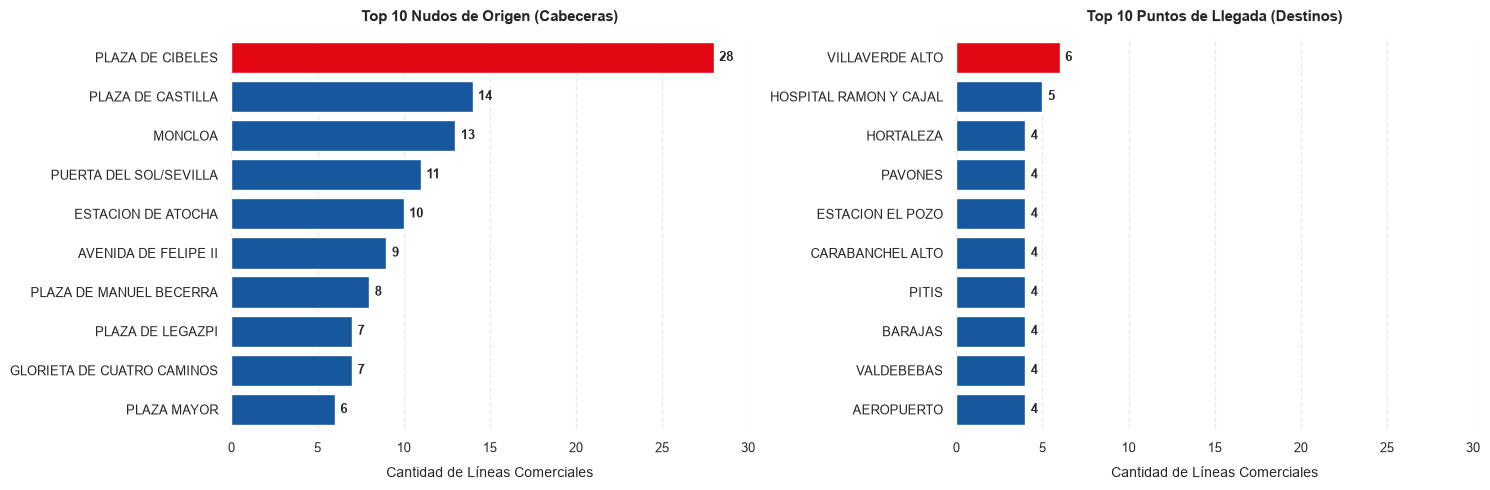

In [ ]:
print("====== REPORTE ANALÍTICO: EXPLOTACIÓN GRÁFICA DE TERMINALES COMERCIALES ======\n")

# 1. Configuración del lienzo corporativo unificado (Estilo whitegrid sutil de alta fidelidad)
sns.set_theme(style="whitegrid", rc={"grid.linestyle": "--", "grid.alpha": 0.4})
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10})

# Creamos un panel horizontal con 1 fila y 2 columnas compartiendo la escala del eje X
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharex=True)

# ==============================================================================
# PANEL IZQUIERDO: TOP 10 NUDOS DE ORIGEN (CABECERAS)
# ==============================================================================
top_cabeceras = routes['cabecera_ruta'].value_counts().head(10).reset_index()
top_cabeceras.columns = ['Cabecera', 'Número de Líneas']

# Dibujamos las barras con un color base corporativo limpio sin argumentos hue redundantes
sns.barplot(x='Número de Líneas', y='Cabecera', data=top_cabeceras, color='#0056B3', ax=ax1)

# Resaltamos el nodo hegemónico (Plaza de Cibeles) en color rojo de forma explícita
for i, patch in enumerate(ax1.patches):
    if top_cabeceras.loc[i, 'Cabecera'] == 'PLAZA DE CIBELES':
        patch.set_facecolor('#E30613')

# Inyectamos las etiquetas numéricas al final de cada barra ordinaria
for container in ax1.containers:
    ax1.bar_label(container, padding=4, weight='bold', fmt='%d', fontsize=9.5)

ax1.set_title("Top 10 Nudos de Origen (Cabeceras)", fontsize=11, weight='bold', pad=12)
ax1.set_xlabel("Cantidad de Líneas Comerciales", fontsize=10, labelpad=8)
ax1.set_ylabel("")

# ==============================================================================
# PANEL DERECHO: TOP 10 PUNTOS DE LLEGADA (DESTINOS)
# ==============================================================================
top_destinos = routes['destino_ruta'].value_counts().head(10).reset_index()
top_destinos.columns = ['Destino', 'Número de Líneas']

# Dibujamos las barras con el color base corporativo unificado
sns.barplot(x='Número de Líneas', y='Destino', data=top_destinos, color='#0056B3', ax=ax2)

# Resaltamos el destino más repetido (Villaverde Alto) en color rojo de forma explícita
for i, patch in enumerate(ax2.patches):
    if top_destinos.loc[i, 'Destino'] == 'VILLAVERDE ALTO':
        patch.set_facecolor('#E30613')

# Inyectamos las etiquetas numéricas de control
for container in ax2.containers:
    ax2.bar_label(container, padding=4, weight='bold', fmt='%d', fontsize=9.5)

ax2.set_title("Top 10 Puntos de Llegada (Destinos)", fontsize=11, weight='bold', pad=12)
ax2.set_xlabel("Cantidad de Líneas Comerciales", fontsize=10, labelpad=8)
ax2.set_ylabel("")

# Fijamos de forma rígida el límite del eje X en 30 para mantener el impacto real del contraste
ax1.set_xlim(0, 30)

# Limpieza de bordes para una visualización ejecutiva descansada
for ax_canvas in [ax1, ax2]:
    ax_canvas.tick_params(axis='both', labelsize=9.5)
    sns.despine(ax=ax_canvas, top=True, right=True, left=True, bottom=True)
    ax_canvas.xaxis.grid(True)
    ax_canvas.yaxis.grid(False) # Desactivamos rejillas horizontales para evitar sobrecarga visual

plt.tight_layout()
plt.show()


#### Conclusiones. Diagnóstico Geo-Operativo: Dispersión Capilar vs. Centralización de la Red

El análisis de frecuencia sobre las terminales de origen y llegada del archivo `routes.txt` revela dos realidades estructurales contundentes sobre el comportamiento del transporte de superficie en Madrid:

1. **Centralización en el Origen (Nudos de Inyección):** El volumen de las cabeceras de origen muestra una concentración asimétrica liderada por la **Plaza de Cibeles (28 líneas)**, seguida de los grandes intercambiadores intermodales de la corona norte y oeste como **Plaza de Castilla (14 líneas)** y **Moncloa (13 líneas)**, y nudos históricos del centro como **Puerta del Sol / Sevilla (11 líneas)** y **Atocha (10 líneas)**. Esto demuestra que la EMT de Madrid planifica la entrada de su flota apoyándose en grandes infraestructuras y puntos neurálgicos centrales que actúan como "grifos" masivos de inyección de autobuses hacia el resto de la ciudad.

2. **Dispersión en el Destino (Capilaridad Residencial):** En contraste con la concentración de los orígenes, el Top 10 de puntos de llegada presenta una distribución fragmentada y monótona, donde destinos periféricos y sanitarios (como **Villaverde Alto** con 6 líneas u **Hospital Ramón y Cajal** con 5) apenas agrupan unas pocas líneas comerciales, empatando el resto en un suelo de 4 líneas. Esto confirma que la red está diseñada para ramificarse de manera capilar hacia la periferia residencial de la ciudad, dispersando los autobuses para maximizar la cobertura en los distritos exteriores.

**Conclusión de Negocio:** La red de superficie se estructura bajo una dinámica de carácter **centrípeto en origen y centrífugo en destino**. Esta asimetría es clave para la ingeniería de características del modelo predictivo: el algoritmo asimilará que los retrasos originados en las cabeceras responderán a la fricción colectiva de grandes nudos de intercambio, mientras que los retrasos en destino reflejarán problemas de tráfico local y capilar de los barrios periféricos.

### Análisis de Centralización Avanzado: Intersección Geográfica y Régimen Horario

Para profundizar en la estructura espacial de la red, se ejecuta una validación cruzada interna intersecando las dos variables operativas desarrolladas en este cuaderno: la dimensión geográfica (`cabecera_ruta`) y la dimensión temporal (`regimen_horario`). 

**Objetivo de la Visualización:** 
El propósito de este análisis es evaluar si la fisonomía de la red se mantiene estable o si experimenta alteraciones al cambiar las ventanas de explotación de la ciudad. Se busca identificar de forma cuantitativa los puntos de inyección masiva de la flota diurna regular frente a los nodos de concentración de la red nocturna. Este contraste es un indicador crítico para la ingeniería de características del modelo predictivo, ya que permitirá ponderar los cuellos de botella y la fricción vial según el comportamiento monocéntrico o policéntrico de las cabeceras de origen.

====== COMPUTANDO ANATOMÍA OPERATIVA DE GRANDES NODOS (PANDAS/SEABORN) ======



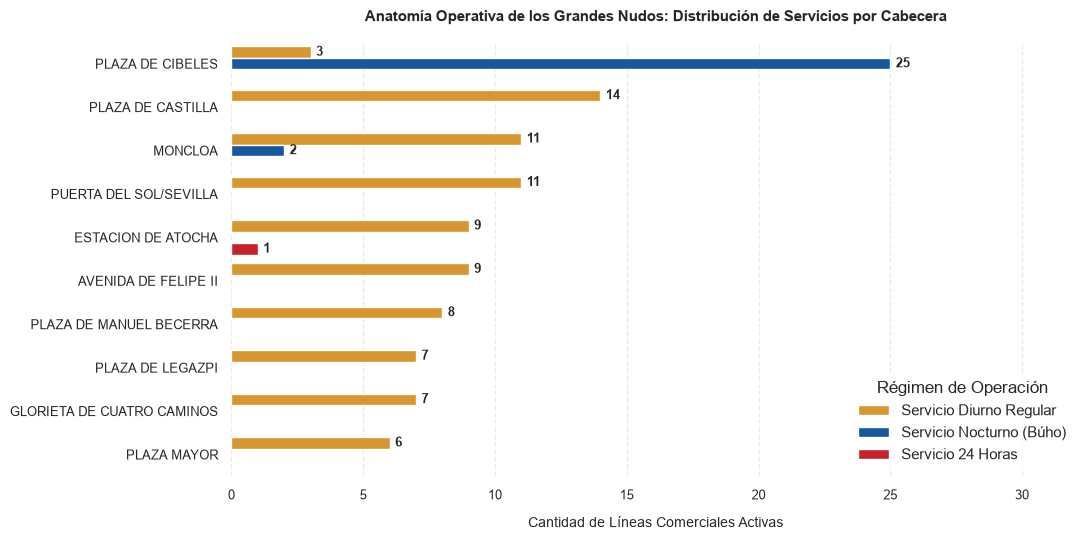

In [15]:
print("====== COMPUTANDO ANATOMÍA OPERATIVA DE GRANDES NODOS (PANDAS/SEABORN) ======\n")

# 1. Selección de las 10 cabeceras principales validadas en el análisis geográfico previo
lista_top_cabeceras = routes['cabecera_ruta'].value_counts().head(10).index.tolist()
df_cruce_cabeceras = routes[routes['cabecera_ruta'].isin(lista_top_cabeceras)].copy()

# 2. Agrupación por nodo y régimen de servicio sobre la matriz local
df_plot_cruce = (
    df_cruce_cabeceras.groupby(['cabecera_ruta', 'regimen_horario'])
    .size()
    .reset_index(name='Total Líneas')
)

# 3. Configuración del lienzo corporativo unificado de alta fidelidad
sns.set_theme(style="whitegrid", rc={"grid.linestyle": "--", "grid.alpha": 0.4})
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10})
plt.figure(figsize=(11, 5.5))

# Matriz de colores oficiales y sobrios: Naranja, Azul EMT y Rojo Exprés
paleta_cruce_corporativa = {
    'Servicio Diurno Regular': '#F39C12',
    'Servicio Nocturno (Búho)': '#0056B3',
    'Servicio 24 Horas': '#E30613'
}

# 4. Renderizado del gráfico de barras agrupadas con orden jerárquico de negocio
ax = sns.barplot(
    x='Total Líneas',
    y='cabecera_ruta',
    hue='regimen_horario',
    data=df_plot_cruce,
    palette=paleta_cruce_corporativa,
    order=lista_top_cabeceras,  # Mapeo del orden jerárquico real de los nudos principales
    hue_order=['Servicio Diurno Regular', 'Servicio Nocturno (Búho)', 'Servicio 24 Horas'],  # Jerarquía lógica de la leyenda
    errorbar=None
)

# Inyección de las etiquetas numéricas exactas al final de cada barra agrupada
for container in ax.containers:
    ax.bar_label(container, padding=4, weight='bold', fmt='%d', fontsize=9.5)

plt.title("Anatomía Operativa de los Grandes Nudos: Distribución de Servicios por Cabecera", fontsize=11, weight='bold', pad=15)
plt.xlabel("Cantidad de Líneas Comerciales Activas", fontsize=10, labelpad=10)
plt.ylabel("")

# Margen de seguridad en el eje horizontal para evitar el truncado de textos de Cibeles
plt.xlim(0, routes['cabecera_ruta'].value_counts().max() * 1.15)

# Limpieza de bordes y rejillas para acabado ejecutivo descansado
ax.tick_params(axis='both', labelsize=9.5)
sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
ax.xaxis.grid(True)
ax.yaxis.grid(False)

# Ubicación de la leyenda en la esquina inferior derecha para evitar solapamientos con los datos
plt.legend(title='Régimen de Operación', loc='lower right', frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()


#### Conclusiones Forenses del Cruce Territorial y Horario de Cabeceras

El desglose del régimen de operación sobre los diez principales nudos de origen revela un comportamiento asimétrico y dual en el diseño de la red de transporte de superficie de la capital:

1. **La Estructura Monocéntrica Nocturna (El Eje Hegemónico de Cibeles):** La validación cruzada identifica a la **Plaza de Cibeles** como el núcleo absoluto de la red de madrugada, concentrando la inmensa mayoría de los trayectos nocturnos (*Búhos*) de la flota y registrando una actividad diurno-comercial marginal. Esto describe un patrón radial centralizado rígido: durante la noche, el transporte urbano de Madrid elimina los nodos policéntricos dispersos y centraliza la inyección de sus unidades en un único punto neurálgico del casco histórico.

2. **La Estructura Policéntrica Diurno-Comercial (Nodos Intermodales Periféricos):** Por el contrario, los grandes intercambiadores de transporte estratégicos de la corona exterior como **Plaza de Castilla** o **Moncloa** actúan como monopolios del servicio diurno regular, desplomándose a cero o a valores mínimos en la franja nocturna. Esto demuestra que la ciudad activa diurna es policéntrica y responde a flujos vinculados a los grandes corredores laborales y universitarios exteriores.

**Valor de Modelado Predictivo:** Esta segmentación cruzada dota al pipeline de una capacidad de discriminación fundamental. Los algoritmos de aprendizaje supervisado asimilarán que registrar un viaje con origen en Plaza de Castilla en horario diurno implica absorber la máxima varianza por congestión de hora punta, mientras que ese mismo origen de madrugada es inexistente. En cambio, para la Plaza de Cibeles, el riesgo analítico de retrasos e inercias horarias se desplazará de forma exclusiva hacia la ventana de operación de la madrugada.

##### Auditoría de la Infraestructura Nocturna Descentralizada

Al analizar la interacción espacial de la validación cruzada, se identifica una concentración asimétrica en la planificación nocturna de Madrid liderada por la Plaza de Cibeles. Con el fin de evaluar si la red nocturna posee una estructura estrictamente monocéntrica o si convive con nodos de descentralización menores distribuidos en la corona exterior que se hayan quedado fuera del corte del volumen principal, se procede a ejecutar una auditoría de cierre.

Se implementa un bloque de código formal para cuantificar el inventario total de la flota activa de la EMT de Madrid y aislar, de manera explícita, el catálogo completo de líneas nocturnas que operan de madrugada estableciendo sus terminales de origen fuera del eje hegemónico de la Plaza de Cibeles.

In [17]:
print("====== AUDITORÍA GLOBAL DE LA FLOTA COMERCIAL ACTIVA (EMT) ======\n")

# 1. Cómputo del volumen total y distribución porcentual de la flota por régimen horario
recuento_flota = routes['regimen_horario'].value_counts()
for regimen, total in recuento_flota.items():
    porcentaje = (total / len(routes)) * 100
    print(f"-> {regimen}: {total} líneas ({porcentaje:.1f}%)")
print(f"TOTAL DE LA FLOTA EN PRODUCCIÓN: {len(routes)} líneas comerciales.\n")

# 2. Aislamiento y extracción automatizada de la estructura nocturna descentralizada
df_nocturnos = routes[routes['regimen_horario'] == 'Servicio Nocturno (Búho)']
nocturnos_descentralizados = df_nocturnos[df_nocturnos['cabecera_ruta'] != 'PLAZA DE CIBELES']

print("====== DETECCIÓN OPERATIVA: ITINERARIOS NOCTURNOS DESCENTRALIZADOS ======")
# Despliegue visual enriquecido mediante display del sub-DataFrame vectorizado
columnas_visor_final = ['route_short_name', 'cabecera_ruta', 'destino_ruta']
display(nocturnos_descentralizados[columnas_visor_final].sort_values(by='route_short_name'))

====== AUDITORÍA GLOBAL DE LA FLOTA COMERCIAL ACTIVA (EMT) ======

-> Servicio Diurno Regular: 203 líneas (86.0%)
-> Servicio Nocturno (Búho): 32 líneas (13.6%)
-> Servicio 24 Horas: 1 líneas (0.4%)
TOTAL DE LA FLOTA EN PRODUCCIÓN: 236 líneas comerciales.

====== DETECCIÓN OPERATIVA: ITINERARIOS NOCTURNOS DESCENTRALIZADOS ======


,route_short_name,cabecera_ruta,destino_ruta
213,N25,PLAZA DE ALONSO MARTINEZ,VILLA DE VALLECAS
214,N26,PLAZA DE ALONSO MARTINEZ,ALUCHE
216,N28,MONCLOA,ARAVACA
219,N31,MONCLOA,EL PARDO
220,N32,AVENIDA DE AMERICA,AEROPUERTO
217,NC1,CUATRO CAMINOS,ESTACION DE ATOCHA
218,NC2,CUATRO CAMINOS,ESTACION DE ATOCHA


#### Nota Analítica: Caracterización de la Infraestructura Nocturna Descentralizada

Los resultados de la auditoría confirman la existencia de **32 líneas nocturnas globales** (el 13.6% de la flota total) e identifican con precisión matemática las **7 líneas específicas que operan de forma descentralizada de la Plaza de Cibeles**.

Al analizar las terminales de estas 7 excepciones geográficas, se demuestra que la descentralización de la madrugada responde a patrones de planificación urbana sumamente estratégicos vinculados a infraestructuras intermodales, terminales ferroviarias y conectividad de distritos singulares:

1. **Ejes de Alivio y Conectividad Periférica desde Moncloa (N28 y N31):** Estas líneas conectan la corona oeste con distritos exteriores alejados como *Aravaca* y *El Pardo*, garantizando el transporte nocturno en corredores que no dependen del eje centralizado de Cibeles.

2. **Ejes de Alivio desde el Nodo de Alonso Martínez (N25 y N26):** Operan como un punto de inyección complementario al casco histórico para canalizar flujos nocturnos directos hacia grandes distritos residenciales de la periferia como *Villa de Vallecas* y *Aluche*.

3. **Ejes de Interconexión de Terminales Ferroviarias (NC1 y NC2):** Configuran las líneas circulares nocturnas oficiales que enlazan de forma continua dos de los nudos estratégicos más transitados de Madrid: el intercambiador de *Cuatro Caminos* y la *Estación de Atocha*.

4. **Eje Logístico Aeroportuario (N32):** Conecta de forma directa el intercambiador de *Avenida de América* con el *Aeropuerto de Barajas*, garantizando un cordón de movilidad de pasajeros y trabajadores aéreos durante las horas de cierre de la red diurna.

**Impacto en el Modelo Predictivo:** Este hallazgo demuestra al algoritmo que la red nocturna posee una varianza de diseño que debe aislarse. Los algoritmos de aprendizaje supervisado asimilarán que los retrasos en las 25 líneas principales de Cibeles responderán a la fricción de grandes masas de usuarios de ocio nocturno en el centro, mientras que el comportamiento de regularidad de estas 7 líneas descentralizadas estará severamente condicionado por la logística operativa de los intercambiadores periféricos, las estaciones de tren y los horarios de los vuelos del aeropuerto.

**Conclusión del Apartado:** Con la normalización de los campos de texto, la inyección del régimen horario y el desglose geo-operativo de las terminales, la matriz de rutas se consolida en un estado inmaculado compuesto por **236 filas y exactamente 6 columnas de producción**, sirviendo como un catálogo maestro relacional óptimo para el pipeline global.


---
> **Atribución de Fuente de Datos:** *Powered by [EMT de Madrid](http://www.emtmadrid.es)* (Portal de Datos Abiertos MobilityLabs / Ayuntamiento de Madrid).